# Assignment 4: Automated Insight Generation (Auto-Analytics Engine)

This notebook ingests a district-level healthcare CSV and automatically finds **trends, outliers, correlations and threshold breaches**, then writes human-readable insights. Nothing is hardcoded: every district name and number in the text comes from the data.

**Sections:** A. Load and validate, B. Trends, C. Outliers, D. Correlation, E. Insight generation, F. Visualization and interactive filters, then export.

In [1]:
# Setup
import io, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

## Engine code
The functions below do all the analysis. Each section is explained where it is used.

In [2]:
INDICATORS = ["anc_coverage", "institutional_delivery",
              "immunization", "high_risk_cases"]

### Part A: load & validate

In [3]:
# ---------- Part A: load & validate ----------
def load_data(path="data.csv"):
    return pd.read_csv(path)


def validate(df):
    print(df.head())
    df.info()
    missing = df.isna().sum()
    print(missing)
    return missing

### Severity (derived from thresholds, no magic numbers)

In [4]:
# ---------- Severity (derived from thresholds, no magic numbers) ----------
def severity_from_ratio(ratio, medium_at=1.5, high_at=2.5):
    """ratio = how many times the value exceeds its own threshold."""
    if ratio >= high_at:
        return "High"
    if ratio >= medium_at:
        return "Medium"
    return "Low"

### Part B: trends

In [5]:
# ---------- Part B: trends ----------
def detect_trends(df, indicators, threshold=10.0):
    cols = ["district", "indicator", "month", "prev", "value",
            "pct_change", "is_significant"]
    rows = []
    d = df.sort_values(["district", "month"])
    for ind in indicators:
        for dist, g in d.groupby("district"):
            g = g[["month", ind]].dropna().reset_index(drop=True)
            for i in range(1, len(g)):
                prev, cur = g.loc[i - 1, ind], g.loc[i, ind]
                if prev == 0:
                    continue
                pct = (cur - prev) / prev * 100
                rows.append({"district": dist, "indicator": ind,
                             "month": g.loc[i, "month"], "prev": prev,
                             "value": cur, "pct_change": pct,
                             "is_significant": abs(pct) >= threshold})
    return pd.DataFrame(rows, columns=cols)

### Part C: outliers

In [6]:
# ---------- Part C: outliers ----------
def detect_outliers(df, indicators, method="IQR", k=1.5, z_th=2.5):
    cols = ["district", "indicator", "month", "value", "mean", "z",
            "ratio", "method"]
    rows = []
    for ind in indicators:
        s = df[ind].dropna()
        if len(s) < 4:
            continue
        mean, std = s.mean(), s.std()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - k * iqr, q3 + k * iqr
        for _, r in df.dropna(subset=[ind]).iterrows():
            v = r[ind]
            z = (v - mean) / std if std > 0 else 0.0
            ratio = None
            if method == "IQR":
                if v < low or v > high:
                    dist = (low - v) if v < low else (v - high)
                    ratio = 1 + dist / max(k * iqr, 1e-9)
            else:
                if abs(z) >= z_th:
                    ratio = abs(z) / z_th
            if ratio is not None:
                rows.append({"district": r["district"], "indicator": ind,
                             "month": r["month"], "value": v, "mean": mean,
                             "z": z, "ratio": ratio, "method": method})
    return pd.DataFrame(rows, columns=cols)

### Absolute-limit breaches

In [7]:
# ---------- Absolute-limit breaches ----------
def detect_breaches(df, limits, ref_pct=10.0):
    """limits = {indicator: ("below"|"above", limit)}"""
    cols = ["district", "indicator", "month", "value", "limit", "kind",
            "gap_pct", "ratio"]
    rows = []
    for ind, (kind, lim) in limits.items():
        if ind not in df.columns or lim == 0:
            continue
        for _, r in df.dropna(subset=[ind]).iterrows():
            v = r[ind]
            breach = (kind == "below" and v < lim) or \
                     (kind == "above" and v > lim)
            if breach:
                gap = abs(v - lim) / abs(lim) * 100
                rows.append({"district": r["district"], "indicator": ind,
                             "month": r["month"], "value": v, "limit": lim,
                             "kind": kind, "gap_pct": gap,
                             "ratio": gap / ref_pct})
    return pd.DataFrame(rows, columns=cols)

### Part D: correlation

In [8]:
# ---------- Part D: correlation ----------
def correlation(df, indicators, th=0.7):
    corr = df[indicators].corr()
    pairs = []
    for i, a in enumerate(indicators):
        for b in indicators[i + 1:]:
            r = corr.loc[a, b]
            if pd.notna(r) and abs(r) >= th:
                pairs.append({"a": a, "b": b, "r": r})
    return corr, pd.DataFrame(pairs, columns=["a", "b", "r"])

### Part E: insight generation

In [9]:
# ---------- Part E: insight generation ----------
def build_insights(df, indicators, p):
    """p = dict of thresholds. Returns dict of all intermediate results."""
    med, high = p["medium_at"], p["high_at"]
    sev = lambda ratio: severity_from_ratio(ratio, med, high)
    items = []

    trends = detect_trends(df, indicators, p["trend_th"])
    for r in trends[trends.is_significant].itertuples():
        word = "dropped" if r.pct_change < 0 else "rose"
        items.append({
            "type": "trend", "indicator": r.indicator, "entity": r.district,
            "period": r.month, "value": r.value, "prev_value": r.prev,
            "change_pct": round(r.pct_change, 1),
            "severity": sev(abs(r.pct_change) / p["trend_th"]),
            "explanation": (f"{r.district} {r.indicator} {word} by "
                            f"{abs(r.pct_change):.1f}% compared to the previous "
                            f"month ({r.prev:g} to {r.value:g}), exceeding the "
                            f"{p['trend_th']:g}% significant-change threshold.")})

    outl = detect_outliers(df, indicators, p["method"], p["iqr_k"], p["z_th"])
    for r in outl.itertuples():
        side = "below" if r.value < r.mean else "above"
        items.append({
            "type": "outlier", "indicator": r.indicator, "entity": r.district,
            "period": r.month, "value": r.value,
            "prev_value": round(r.mean, 1),
            "change_pct": round((r.value - r.mean) / r.mean * 100, 1)
            if r.mean else None,
            "severity": sev(r.ratio),
            "explanation": (f"{r.district}'s {r.indicator} of {r.value:g} is "
                            f"{abs(r.z):.1f}\u03c3 {side} the overall mean "
                            f"({r.mean:.0f}) [{r.method} rule], flagging for "
                            f"review.")})

    breaches = detect_breaches(df, p.get("limits", {}), p["trend_th"])
    for r in breaches.itertuples():
        items.append({
            "type": "threshold_breach", "indicator": r.indicator,
            "entity": r.district, "period": r.month, "value": r.value,
            "prev_value": r.limit, "change_pct": round(
                (r.value - r.limit) / r.limit * 100, 1),
            "severity": sev(r.ratio),
            "explanation": (f"{r.district} {r.indicator} is {r.value:g}, "
                            f"{r.kind} the allowed limit of {r.limit:g} "
                            f"by {r.gap_pct:.1f}%.")})

    corr, pairs = correlation(df, indicators, p["corr_th"])
    if len(df):
        period = f"{df.month.min()}..{df.month.max()}"
    else:
        period = "n/a"
    for r in pairs.itertuples():
        direction = "negative" if r.r < 0 else "positive"
        items.append({
            "type": "correlation", "indicator": f"{r.a}:{r.b}",
            "entity": "All districts", "period": period,
            "value": f"r={r.r:.2f}", "prev_value": None, "change_pct": None,
            "severity": sev(abs(r.r) / p["corr_th"]),
            "explanation": (f"{r.a} and {r.b} have a strong {direction} "
                            f"correlation (r={r.r:.2f}, |r| >= "
                            f"{p['corr_th']:g}). Small sample: treat with "
                            f"caution.")})

    cols = ["insight_id", "type", "indicator", "entity", "period", "value",
            "prev_value", "change_pct", "severity", "explanation"]
    ins = pd.DataFrame(items)
    if ins.empty:
        ins = pd.DataFrame(columns=cols)
    else:
        ins.insert(0, "insight_id",
                   [f"INS-{i:04d}" for i in range(1, len(ins) + 1)])
    return {"insights": ins[cols], "trends": trends, "outliers": outl,
            "breaches": breaches, "corr": corr, "pairs": pairs}

## Part A: Load and validate

In [10]:
CSV = """month,district,anc_coverage,institutional_delivery,immunization,high_risk_cases
2026-07,Ahmedabad,85,91,93,10
2026-08,Ahmedabad,69,90,92,13
2026-07,Surat,81,87,91,13
2026-08,Surat,83,89,92,12
2026-07,Vadodara,90,93,96,7
2026-08,Vadodara,91,94,97,6
2026-07,Rajkot,79,85,89,15
2026-08,Rajkot,80,86,90,14
2026-07,Mehsana,84,89,92,11
2026-08,Mehsana,42,88,91,28
2026-07,Bhavnagar,77,82,87,17
2026-08,Bhavnagar,79,84,89,15
"""
# uses data.csv if it exists next to the notebook, else the inline sample
df = load_data("data.csv") if os.path.exists("data.csv") else pd.read_csv(io.StringIO(CSV))
missing = validate(df)

     month   district  anc_coverage  institutional_delivery  immunization  \
0  2026-07  Ahmedabad            85                      91            93   
1  2026-08  Ahmedabad            69                      90            92   
2  2026-07      Surat            81                      87            91   
3  2026-08      Surat            83                      89            92   
4  2026-07   Vadodara            90                      93            96   

   high_risk_cases  
0               10  
1               13  
2               13  
3               12  
4                7  
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   month                   12 non-null     str  
 1   district                12 non-null     str  
 2   anc_coverage            12 non-null     int64
 3   institutional_delivery  12 non-null     int64
 4   immunizat

`head()`, `info()` and the missing-value count are printed above. All counts are 0, so the data is clean.

## Configuration (all thresholds are adjustable)

In [11]:
params = dict(
    trend_th=10,      # % change that counts as significant
    method="IQR",     # "IQR" or "Z-score"
    iqr_k=1.5,        # IQR multiplier
    z_th=2.5,         # z-score threshold
    corr_th=0.70,     # |r| threshold
    medium_at=1.5,    # severity: ratio >= this is Medium
    high_at=2.5,      # severity: ratio >= this is High
    limits={"anc_coverage": ("below", 60.0),        # absolute limits for threshold_breach
            "high_risk_cases": ("above", 25.0)},
)

## Parts B to E: run the engine
Trend, outlier, correlation and threshold-breach detection all feed one insights table.

In [12]:
res = build_insights(df, INDICATORS, params)
insights, corr, pairs = res["insights"], res["corr"], res["pairs"]
print("Significant trends:"); display(res["trends"][res["trends"].is_significant])
print("Outliers:"); display(res["outliers"])
print("Correlation pairs with |r| >= threshold:"); display(pairs)

Significant trends:


,district,indicator,month,prev,value,pct_change,is_significant
0,Ahmedabad,anc_coverage,2026-08,85,69,-18.823529,True
2,Mehsana,anc_coverage,2026-08,84,42,-50.000000,True
18,Ahmedabad,high_risk_cases,2026-08,10,13,30.000000,True
19,Bhavnagar,high_risk_cases,2026-08,17,15,-11.764706,True
20,Mehsana,high_risk_cases,2026-08,11,28,154.545455,True
23,Vadodara,high_risk_cases,2026-08,7,6,-14.285714,True


Outliers:


,district,indicator,month,value,mean,z,ratio,method
0,Ahmedabad,anc_coverage,2026-08,69,78.333333,-0.726666,1.101449,IQR
1,Mehsana,anc_coverage,2026-08,42,78.333333,-2.828806,4.231884,IQR
2,Vadodara,immunization,2026-08,97,91.583333,1.905184,1.266667,IQR
3,Mehsana,high_risk_cases,2026-08,28,13.416667,2.596812,2.039216,IQR


Correlation pairs with |r| >= threshold:


,a,b,r
0,anc_coverage,high_risk_cases,-0.933495
1,institutional_delivery,immunization,0.978608


### Pearson correlation matrix
**Limitation:** the sample has only 2 months x 6 districts = 12 rows, so correlations are unstable and should not be treated as reliable.

In [13]:
display(corr.round(2))

,anc_coverage,institutional_delivery,immunization,high_risk_cases
anc_coverage,1.00,0.28,0.37,-0.93
institutional_delivery,0.28,1.00,0.98,-0.56
immunization,0.37,0.98,1.00,-0.62
high_risk_cases,-0.93,-0.56,-0.62,1.00


### Generated insights

In [14]:
pd.set_option("display.max_colwidth", None)
display(insights)
print(insights.severity.value_counts().to_dict())

,insight_id,type,indicator,entity,period,value,prev_value,change_pct,severity,explanation
0,INS-0001,trend,anc_coverage,Ahmedabad,2026-08,69,85.0,-18.8,Medium,"Ahmedabad anc_coverage dropped by 18.8% compared to the previous month (85 to 69), exceeding the 10% significant-change threshold."
1,INS-0002,trend,anc_coverage,Mehsana,2026-08,42,84.0,-50.0,High,"Mehsana anc_coverage dropped by 50.0% compared to the previous month (84 to 42), exceeding the 10% significant-change threshold."
2,INS-0003,trend,high_risk_cases,Ahmedabad,2026-08,13,10.0,30.0,High,"Ahmedabad high_risk_cases rose by 30.0% compared to the previous month (10 to 13), exceeding the 10% significant-change threshold."
3,INS-0004,trend,high_risk_cases,Bhavnagar,2026-08,15,17.0,-11.8,Low,"Bhavnagar high_risk_cases dropped by 11.8% compared to the previous month (17 to 15), exceeding the 10% significant-change threshold."
4,INS-0005,trend,high_risk_cases,Mehsana,2026-08,28,11.0,154.5,High,"Mehsana high_risk_cases rose by 154.5% compared to the previous month (11 to 28), exceeding the 10% significant-change threshold."
5,INS-0006,trend,high_risk_cases,Vadodara,2026-08,6,7.0,-14.3,Low,"Vadodara high_risk_cases dropped by 14.3% compared to the previous month (7 to 6), exceeding the 10% significant-change threshold."
6,INS-0007,outlier,anc_coverage,Ahmedabad,2026-08,69,78.3,-11.9,Low,"Ahmedabad's anc_coverage of 69 is 0.7σ below the overall mean (78) [IQR rule], flagging for review."
7,INS-0008,outlier,anc_coverage,Mehsana,2026-08,42,78.3,-46.4,High,"Mehsana's anc_coverage of 42 is 2.8σ below the overall mean (78) [IQR rule], flagging for review."
8,INS-0009,outlier,immunization,Vadodara,2026-08,97,91.6,5.9,Low,"Vadodara's immunization of 97 is 1.9σ above the overall mean (92) [IQR rule], flagging for review."
9,INS-0010,outlier,high_risk_cases,Mehsana,2026-08,28,13.4,108.7,Medium,"Mehsana's high_risk_cases of 28 is 2.6σ above the overall mean (13) [IQR rule], flagging for review."


{'Low': 7, 'High': 5, 'Medium': 2}


**How severity is derived:** ratio = measured value / its own threshold (trend: |pct change| / threshold; outlier: z / z threshold or distance past the IQR fence; correlation: |r| / threshold). Ratio >= 2.5 is High, >= 1.5 is Medium, else Low. The cut-offs are parameters, not magic numbers.

## Part F: Visualizations

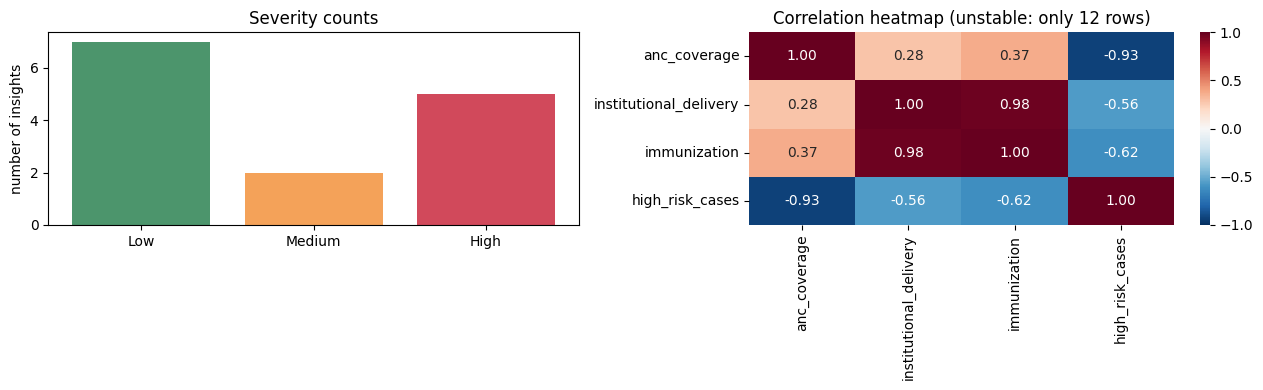

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts = insights.severity.value_counts().reindex(["Low", "Medium", "High"], fill_value=0)
ax[0].bar(counts.index, counts.values, color=["#4c956c", "#f4a259", "#d1495b"])
ax[0].set_title("Severity counts"); ax[0].set_ylabel("number of insights")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Correlation heatmap (unstable: only 12 rows)")
plt.tight_layout(); plt.show()

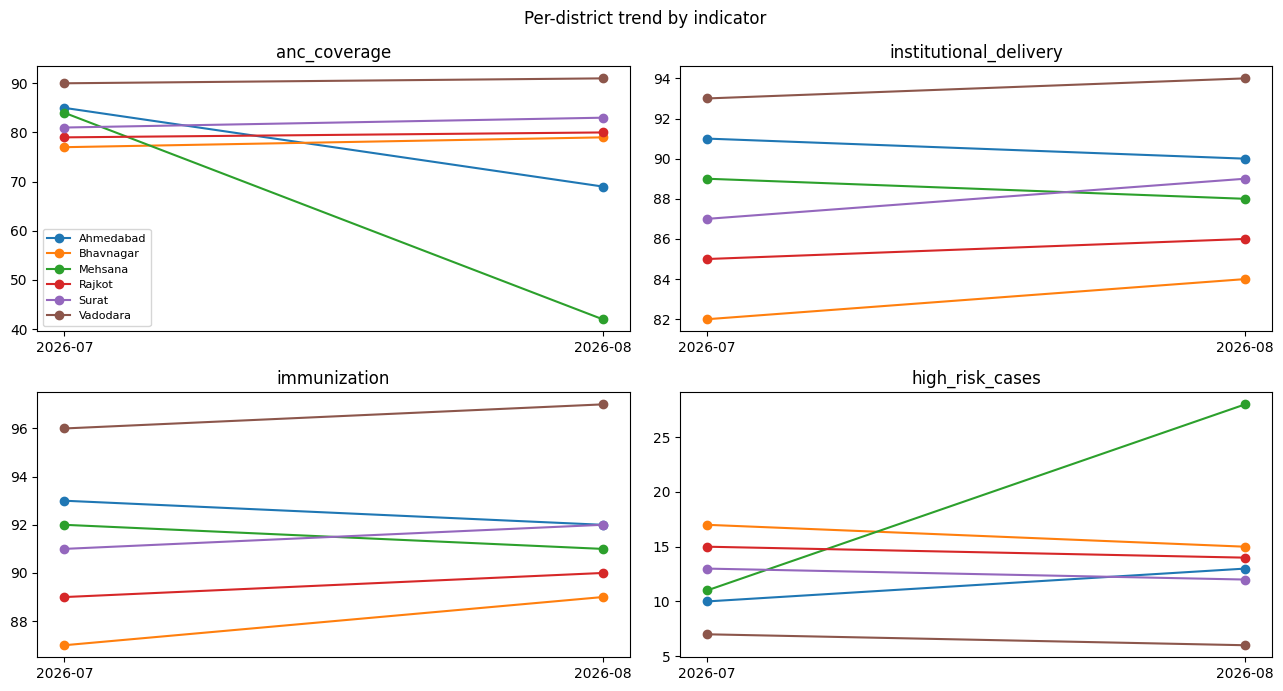

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for a, ind in zip(axes.ravel(), INDICATORS):
    for dist, g in df.sort_values("month").groupby("district"):
        a.plot(g["month"], g[ind], marker="o", label=dist)
    a.set_title(ind)
axes[0, 0].legend(fontsize=8)
plt.suptitle("Per-district trend by indicator"); plt.tight_layout(); plt.show()

## Interactive filters and sliders
Change the filters or sliders below. The insights table updates live.

In [17]:
import ipywidgets as w
dist_w = w.SelectMultiple(options=sorted(df.district.unique()), value=tuple(sorted(df.district.unique())), description="District")
mon_w = w.SelectMultiple(options=sorted(df.month.unique()), value=tuple(sorted(df.month.unique())), description="Month")
ind_w = w.SelectMultiple(options=INDICATORS, value=tuple(INDICATORS), description="Indicator")
trend_w = w.IntSlider(value=10, min=1, max=50, description="Trend %")
meth_w = w.ToggleButtons(options=["IQR", "Z-score"], description="Outlier")
k_w = w.FloatSlider(value=1.5, min=0.5, max=3, step=0.1, description="IQR k")
z_w = w.FloatSlider(value=2.5, min=1, max=4, step=0.1, description="Z thr")
r_w = w.FloatSlider(value=0.7, min=0.1, max=1, step=0.05, description="|r| thr")

def run(districts, months, inds, trend, method, k, z, r):
    f = df[df.district.isin(districts) & df.month.isin(months)]
    if f.empty or not inds:
        print("Select at least one district, month and indicator."); return
    p = dict(params, trend_th=trend, method=method, iqr_k=k, z_th=z, corr_th=r)
    out = build_insights(f, list(inds), p)["insights"]
    print(f"{len(out)} insights | " + str(out.severity.value_counts().to_dict()))
    display(out)

w.interactive_output  # widgets are optional; works in Jupyter / Colab
ui = w.VBox([w.HBox([dist_w, mon_w, ind_w]), w.HBox([trend_w, meth_w]), w.HBox([k_w, z_w, r_w])])
out = w.interactive_output(run, dict(districts=dist_w, months=mon_w, inds=ind_w, trend=trend_w, method=meth_w, k=k_w, z=z_w, r=r_w))
display(ui, out)

Output()

## Export outputs

In [18]:
insights.to_csv("insights.csv", index=False)
insights.to_json("sample_insights.json", orient="records", indent=2)
corr.to_csv("correlation_matrix.csv")
print("Saved: insights.csv, sample_insights.json, correlation_matrix.csv")

Saved: insights.csv, sample_insights.json, correlation_matrix.csv


## Summary

- **Trends:** Ahmedabad ANC coverage fell 18.8% (85 to 69); Mehsana high-risk cases rose 154.5% (11 to 28).
- **Outlier:** Mehsana ANC coverage of 42 is far below the other districts.
- **Correlation:** ANC coverage and high-risk cases move in opposite directions (r about -0.93), but with only 12 rows this is indicative, not conclusive.